# Task 4: High-Imbalance Clinical Disease Predictor

**Progree Machine Learning Internship** · Omar Hatem Mohamed Emam

**Objective.** Build an end-to-end classifier that flags pathological fetal heart rate traces in cardiotocography (CTG) data, where the positive class is rare.

**Approach.**
- Data: UCI Cardiotocography dataset (2,126 CTG records, 21 features). Target: pathological trace (NSP = 3) against normal or suspect traces.
- Imbalance handling: none (baseline), class weights, and SMOTE applied inside each training fold only.
- Models: SVM (RBF kernel), random forest and XGBoost.
- Tuning: stratified 5-fold cross-validation. The selection rule takes the highest mean recall among candidates whose mean precision is at least 0.75.
- Evaluation: each tuned configuration is scored once on a held-out test set (20% of records).

The notebook calls the functions in `src/train.py` with the same seeds and settings, so every number below matches `results/`. The last code cell checks this.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import train as T
import plots as P

SEED, FOLDS, N_ITER, FLOOR = 42, 5, 30, T.PRECISION_FLOOR
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
T.versions()

{'python': '3.13.18',
 'numpy': '2.5.3',
 'pandas': '3.0.5',
 'scikit-learn': '1.9.1',
 'imbalanced-learn': '0.14.2',
 'xgboost': '3.4.1',
 'matplotlib': '3.11.2'}

## 1. Data

In [2]:
df = T.load_data(ROOT / "data" / "fetal_health.csv")
print(df.shape)
df.head()

(2126, 22)


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [3]:
X, y, nsp, data_info = T.prepare_data(df)
data_info

{'n_raw': 2126,
 'n_duplicates_removed': 13,
 'n_records': 2113,
 'n_features': 21,
 'n_missing_values': 0,
 'nsp_counts': {1: 1646, 2: 292, 3: 175},
 'n_positive': 175,
 'prevalence': 0.08282063416942735,
 'imbalance_ratio': 11.074285714285715}

The 13 exact duplicate rows are removed before splitting, so no record can appear in both the training and the test set. There are no missing values. The 21 features, with the codes used by the UCI repository:

In [4]:
pd.DataFrame({"code": list(T.FEATURE_DESCRIPTIONS),
              "description": list(T.FEATURE_DESCRIPTIONS.values())})

,code,description
0,LB,FHR baseline (beats per minute)
1,AC,Accelerations per second
2,FM,Fetal movements per second
3,UC,Uterine contractions per second
4,DL,Light decelerations per second
5,DS,Severe decelerations per second
6,DP,Prolonged decelerations per second
7,ASTV,Percentage of time with abnormal short-term va...
8,MSTV,Mean value of short-term variability
9,ALTV,Percentage of time with abnormal long-term var...


In [5]:
X.describe().T[["mean", "std", "min", "50%", "max"]].round(3)

,mean,std,min,50%,max
LB,133.305,9.837,106.0,133.000,160.000
AC,0.003,0.004,0.0,0.002,0.019
FM,0.010,0.047,0.0,0.000,0.481
UC,0.004,0.003,0.0,0.005,0.015
DL,0.002,0.003,0.0,0.000,0.015
DS,0.000,0.000,0.0,0.000,0.001
DP,0.000,0.001,0.0,0.000,0.005
ASTV,46.994,17.178,12.0,49.000,87.000
MSTV,1.335,0.884,0.2,1.200,7.000
ALTV,9.795,18.337,0.0,0.000,91.000


### Class distribution

Pathological traces are 8.3% of records, about 11 negative records for every positive one.

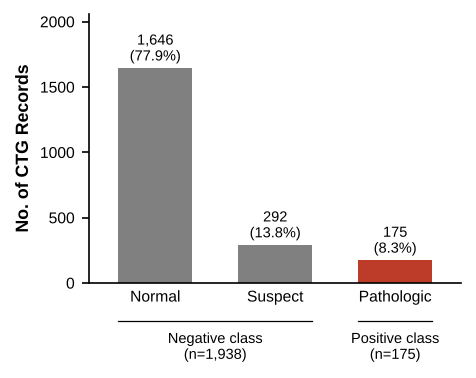

In [6]:
P.plot_class_distribution(data_info["nsp_counts"])
plt.show()

## 2. Train/test split

An 80/20 split, stratified on the three-level NSP label so that normal, suspect and pathological traces keep the same proportions in both parts. The test set is not touched again until section 6.

In [7]:
X_tr, X_te, y_tr, y_te, split_info = T.split_data(X, y, nsp, test_size=0.2, seed=SEED)
split_info

{'test_size': 0.2,
 'n_train': 1690,
 'n_test': 423,
 'train_positive': 140,
 'test_positive': 35,
 'train_nsp_counts': {1: 1316, 2: 234, 3: 140},
 'test_nsp_counts': {1: 330, 2: 58, 3: 35}}

## 3. Pipelines

Each configuration is an `imblearn` pipeline: median imputation, standard scaling, SMOTE (only in the SMOTE configurations) and the classifier. Because SMOTE sits inside the pipeline, synthetic cases are generated from the training folds only, never from validation or test records.

Class weights: `class_weight="balanced"` for the SVM, `class_weight="balanced_subsample"` for the random forest, and `scale_pos_weight` equal to the ratio of negatives to positives for XGBoost.

In [8]:
pos_weight = float((y_tr == 0).sum() / (y_tr == 1).sum())
print(f"scale_pos_weight for XGBoost: {pos_weight:.2f}")
print(T.build_pipeline("XGBoost", "SMOTE", pos_weight, SEED))

scale_pos_weight for XGBoost: 11.07
Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()), ('smote', SMOTE(random_state=42)),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types...=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=No

In [9]:
{model: {k.replace("clf__", ""): v for k, v in space.items()}
 for model, space in T.PARAM_SPACES.items()}

{'SVM': {'C': [0.1, 0.3, 1, 3, 10, 30, 100],
  'gamma': ['scale', 0.003, 0.01, 0.03, 0.1, 0.3]},
 'Random Forest': {'n_estimators': [200, 400],
  'max_depth': [None, 4, 8, 12, 16],
  'min_samples_leaf': [1, 2, 4, 8],
  'max_features': ['sqrt', 0.3, 0.5]},
 'XGBoost': {'n_estimators': [200, 400, 600],
  'max_depth': [2, 3, 4, 6],
  'learning_rate': [0.03, 0.05, 0.1, 0.2],
  'subsample': [0.7, 0.85, 1.0],
  'colsample_bytree': [0.6, 0.8, 1.0],
  'min_child_weight': [1, 3, 5]}}

## 4. Hyperparameter tuning with stratified 5-fold cross-validation

The SVM is searched over its full grid (42 candidates); the random forest and XGBoost by random search (30 candidates each). Every candidate is scored on recall, precision, specificity, F2, ROC-AUC and average precision in each fold.

**Selection rule.** Highest mean recall among candidates whose mean precision is at least 0.75, with ties broken by F2. The precision floor stops the search from buying a small gain in recall with a large number of false alarms.

In [10]:
cv = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
log = T.setup_logging()
searches, summaries = T.tune_all(X_tr, y_tr, cv, n_iter=N_ITER, floor=FLOOR,
                                 seed=SEED, n_jobs=2, log=log)

2026-11-19 11:13:25 | INFO | CV  SVM           | None          |  42 candidates |    4.5 s | recall 0.871 ± 0.054 | precision 0.906 | F2 0.877 | best {'C': 30, 'gamma': 'scale'}


2026-11-19 11:13:29 | INFO | CV  SVM           | Class weights |  42 candidates |    3.8 s | recall 0.907 ± 0.020 | precision 0.810 | F2 0.885 | best {'C': 30, 'gamma': 'scale'}


2026-11-19 11:13:35 | INFO | CV  SVM           | SMOTE         |  42 candidates |    6.0 s | recall 0.907 ± 0.041 | precision 0.752 | F2 0.870 | best {'C': 30, 'gamma': 0.01}


2026-11-19 11:14:14 | INFO | CV  Random Forest | None          |  30 candidates |   39.1 s | recall 0.907 ± 0.041 | precision 0.929 | F2 0.911 | best {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 12}


2026-11-19 11:14:59 | INFO | CV  Random Forest | Class weights |  30 candidates |   45.0 s | recall 0.929 ± 0.025 | precision 0.828 | F2 0.906 | best {'n_estimators': 400, 'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': None}


2026-11-19 11:16:02 | INFO | CV  Random Forest | SMOTE         |  30 candidates |   62.9 s | recall 0.929 ± 0.025 | precision 0.881 | F2 0.918 | best {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 0.3, 'max_depth': None}


2026-11-19 11:16:08 | INFO | CV  XGBoost       | None          |  30 candidates |    5.9 s | recall 0.914 ± 0.032 | precision 0.942 | F2 0.919 | best {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


2026-11-19 11:16:14 | INFO | CV  XGBoost       | Class weights |  30 candidates |    6.5 s | recall 0.943 ± 0.041 | precision 0.884 | F2 0.929 | best {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


2026-11-19 11:16:27 | INFO | CV  XGBoost       | SMOTE         |  30 candidates |   12.7 s | recall 0.936 ± 0.030 | precision 0.899 | F2 0.928 | best {'subsample': 0.85, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


## 5. Cross-validation arrays

Recall of the selected candidate in each of the five validation folds. Each fold holds 28 pathological traces, so one missed trace changes the fold recall by 0.036.

In [11]:
T.folds_table(summaries, "recall").round(3)

,model,strategy,fold_1,fold_2,fold_3,fold_4,fold_5,mean,sd
0,SVM,None,0.857,0.964,0.857,0.857,0.821,0.871,0.054
1,SVM,Class weights,0.929,0.929,0.893,0.893,0.893,0.907,0.020
2,SVM,SMOTE,0.929,0.964,0.857,0.893,0.893,0.907,0.041
3,Random Forest,None,0.893,0.929,0.857,0.893,0.964,0.907,0.041
4,Random Forest,Class weights,0.929,0.964,0.929,0.893,0.929,0.929,0.025
5,Random Forest,SMOTE,0.929,0.964,0.929,0.893,0.929,0.929,0.025
6,XGBoost,None,0.893,0.893,0.929,0.893,0.964,0.914,0.032
7,XGBoost,Class weights,0.929,0.964,0.929,0.893,1.000,0.943,0.041
8,XGBoost,SMOTE,0.964,0.929,0.929,0.893,0.964,0.936,0.030


In [12]:
T.folds_table(summaries, "precision").round(3)

,model,strategy,fold_1,fold_2,fold_3,fold_4,fold_5,mean,sd
0,SVM,None,0.960,0.871,0.889,0.960,0.852,0.906,0.051
1,SVM,Class weights,0.839,0.897,0.806,0.833,0.676,0.810,0.082
2,SVM,SMOTE,0.839,0.771,0.686,0.806,0.658,0.752,0.078
3,Random Forest,None,0.962,0.929,0.960,0.862,0.931,0.929,0.040
4,Random Forest,Class weights,0.929,0.844,0.812,0.833,0.722,0.828,0.074
5,Random Forest,SMOTE,0.963,0.900,0.812,0.833,0.897,0.881,0.060
6,XGBoost,None,0.962,0.962,0.963,0.893,0.931,0.942,0.031
7,XGBoost,Class weights,0.929,0.931,0.929,0.833,0.800,0.884,0.063
8,XGBoost,SMOTE,0.964,0.929,0.867,0.833,0.900,0.899,0.051


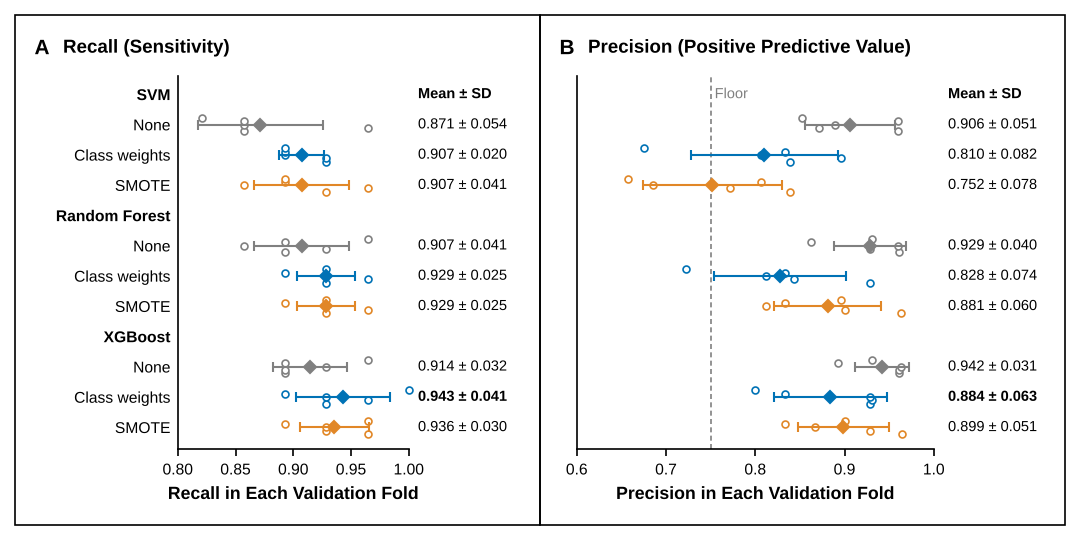

Best strategy per model: {'SVM': 'Class weights', 'Random Forest': 'SMOTE', 'XGBoost': 'Class weights'}
Final model: XGBoost + Class weights


In [13]:
final_key = T.select_final(summaries, FLOOR)
best = T.best_strategy_per_model(summaries, FLOOR)
P.plot_cv_folds(summaries, final_key, FLOOR)
plt.show()
print("Best strategy per model:", best)
print("Final model:", " + ".join(final_key))

### How much does the precision floor matter?

The same rule applied to all 306 tuned candidates, with a floor of 0.5 and with the floor used here (0.75). Totals are summed over the five validation folds (140 pathological and 1,550 other traces).

In [14]:
table = T.search_table(searches, FLOOR)
pd.DataFrame(T.floor_sensitivity(table, [0.5, FLOOR]))

,floor,model,strategy,params,cv_recall,cv_precision,cv_specificity,cv_f2,cv_tp_total,cv_fp_total
0,0.50,SVM,Class weights,"{'C': 0.3, 'gamma': 0.03}",0.971,0.573,0.932,0.850,136,105
1,0.75,XGBoost,Class weights,"{'subsample': 1.0, 'n_estimators': 400, 'min_c...",0.943,0.884,0.988,0.929,132,18


## 6. Test-set evaluation

Each tuned configuration, refitted on the whole training set, is scored once on the 423 held-out records (35 pathological). The final model was fixed by the cross-validation rule before this step.

In [15]:
tests = T.evaluate_all(searches, X_te, y_te, SEED, log)
comparison = T.comparison_table(summaries, tests, final_key)
comparison[["model", "strategy", "cv_recall_mean", "cv_precision_mean", "test_recall",
            "test_precision", "test_specificity", "test_f2", "test_roc_auc",
            "test_average_precision", "tp", "fn", "fp", "tn"]].round(3)

2026-11-19 11:16:30 | INFO | TEST SVM           | None          | recall 0.943 (33/35) | precision 0.917 | specificity 0.992 | F2 0.938 | ROC-AUC 0.996 | AP 0.959


2026-11-19 11:16:33 | INFO | TEST SVM           | Class weights | recall 0.943 (33/35) | precision 0.892 | specificity 0.990 | F2 0.932 | ROC-AUC 0.996 | AP 0.961


2026-11-19 11:16:36 | INFO | TEST SVM           | SMOTE         | recall 0.914 (32/35) | precision 0.744 | specificity 0.972 | F2 0.874 | ROC-AUC 0.991 | AP 0.926


2026-11-19 11:16:40 | INFO | TEST Random Forest | None          | recall 0.971 (34/35) | precision 0.944 | specificity 0.995 | F2 0.966 | ROC-AUC 0.999 | AP 0.993


2026-11-19 11:16:43 | INFO | TEST Random Forest | Class weights | recall 0.943 (33/35) | precision 0.825 | specificity 0.982 | F2 0.917 | ROC-AUC 0.997 | AP 0.978


2026-11-19 11:16:46 | INFO | TEST Random Forest | SMOTE         | recall 0.914 (32/35) | precision 0.889 | specificity 0.990 | F2 0.909 | ROC-AUC 0.998 | AP 0.981


2026-11-19 11:16:49 | INFO | TEST XGBoost       | None          | recall 0.829 (29/35) | precision 1.000 | specificity 1.000 | F2 0.858 | ROC-AUC 1.000 | AP 0.996


2026-11-19 11:16:52 | INFO | TEST XGBoost       | Class weights | recall 0.943 (33/35) | precision 0.971 | specificity 0.997 | F2 0.948 | ROC-AUC 1.000 | AP 0.997


2026-11-19 11:16:55 | INFO | TEST XGBoost       | SMOTE         | recall 0.971 (34/35) | precision 0.919 | specificity 0.992 | F2 0.960 | ROC-AUC 0.999 | AP 0.994


,model,strategy,cv_recall_mean,cv_precision_mean,test_recall,test_precision,test_specificity,test_f2,test_roc_auc,test_average_precision,tp,fn,fp,tn
0,SVM,None,0.871,0.906,0.943,0.917,0.992,0.938,0.996,0.959,33,2,3,385
1,SVM,Class weights,0.907,0.810,0.943,0.892,0.990,0.932,0.996,0.961,33,2,4,384
2,SVM,SMOTE,0.907,0.752,0.914,0.744,0.972,0.874,0.991,0.926,32,3,11,377
3,Random Forest,None,0.907,0.929,0.971,0.944,0.995,0.966,0.999,0.993,34,1,2,386
4,Random Forest,Class weights,0.929,0.828,0.943,0.825,0.982,0.917,0.997,0.978,33,2,7,381
5,Random Forest,SMOTE,0.929,0.881,0.914,0.889,0.990,0.909,0.998,0.981,32,3,4,384
6,XGBoost,None,0.914,0.942,0.829,1.000,1.000,0.858,1.000,0.996,29,6,0,388
7,XGBoost,Class weights,0.943,0.884,0.943,0.971,0.997,0.948,1.000,0.997,33,2,1,387
8,XGBoost,SMOTE,0.936,0.899,0.971,0.919,0.992,0.960,0.999,0.994,34,1,3,385


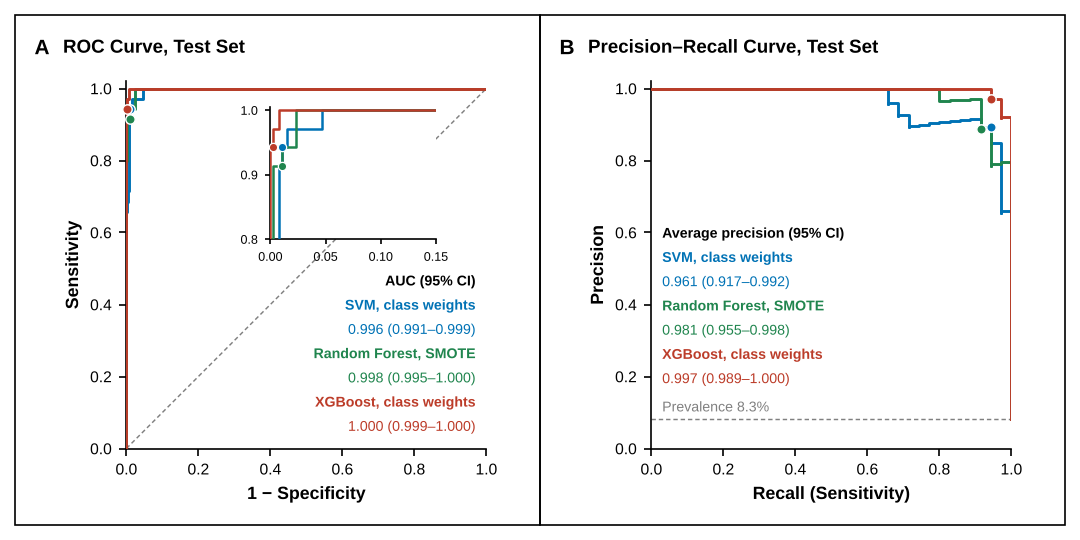

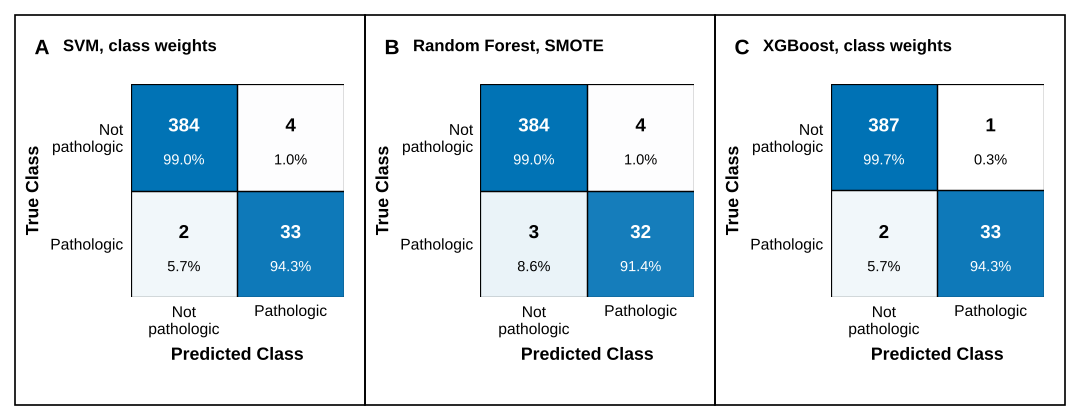

In [16]:
labels = {m: P.config_label(m, best[m]) for m in T.MODELS}
curves = {m: T.test_curves(searches[(m, best[m])].best_estimator_, X_te, y_te) for m in T.MODELS}
prevalence = split_info["test_positive"] / split_info["n_test"]
P.plot_test_curves(curves, {m: tests[(m, best[m])] for m in T.MODELS}, labels, prevalence)
plt.show()
P.plot_confusion_matrices({m: tests[(m, best[m])] for m in T.MODELS}, labels)
plt.show()

In [17]:
t = tests[final_key]
names = ["recall", "precision", "specificity", "roc_auc", "average_precision"]
pd.DataFrame({"estimate": [t[n] for n in names],
              "ci95_low": [t[f"{n}_ci95"][0] for n in names],
              "ci95_high": [t[f"{n}_ci95"][1] for n in names]},
             index=names).round(3)

,estimate,ci95_low,ci95_high
recall,0.943,0.814,0.984
precision,0.971,0.851,0.995
specificity,0.997,0.986,1.000
roc_auc,1.000,0.999,1.000
average_precision,0.997,0.989,1.000


## 7. Which features drive the final model?

Permutation importance on the test set: the fall in average precision when one feature is shuffled, over 30 repeats.

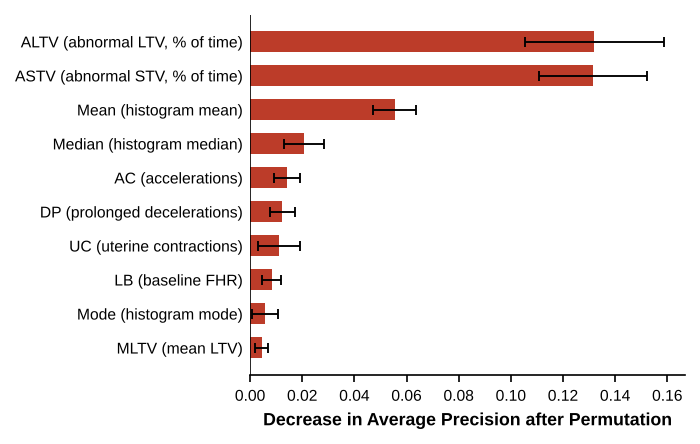

,feature,description,importance_mean,importance_sd
0,ALTV,Percentage of time with abnormal long-term var...,0.132,0.027
1,ASTV,Percentage of time with abnormal short-term va...,0.131,0.021
2,Mean,Histogram mean,0.055,0.008
3,Median,Histogram median,0.021,0.008
4,AC,Accelerations per second,0.014,0.005
5,DP,Prolonged decelerations per second,0.012,0.005
6,UC,Uterine contractions per second,0.011,0.008
7,LB,FHR baseline (beats per minute),0.008,0.004
8,Mode,Histogram mode,0.006,0.005
9,MLTV,Mean value of long-term variability,0.004,0.003


In [18]:
final_model = searches[final_key].best_estimator_
imp = T.importance_table(final_model, X_te, y_te, SEED)
P.plot_importance(imp, P.MODEL_COLORS[final_key[0]])
plt.show()
imp.head(10).round(3)

## 8. Check against the script run

In [19]:
saved = json.loads((ROOT / "results" / "metrics.json").read_text())
saved_cfg = {(c["model"], c["strategy"]): c for c in saved["configs"]}
for k in summaries:
    for m in T.SCORERS:
        assert np.allclose(saved_cfg[k]["cv_folds"][m], summaries[k]["cv_folds"][m]), (k, m)
    for m in ("recall", "precision", "specificity", "f2", "roc_auc", "average_precision",
              "tp", "fn", "fp", "tn"):
        assert np.isclose(saved_cfg[k]["test"][m], tests[k][m]), (k, m)
assert (saved["final_model"]["model"], saved["final_model"]["strategy"]) == final_key
assert np.allclose([r["importance_mean"] for r in saved["permutation_importance"]],
                   imp["importance_mean"])
print("All cross-validation and test numbers match results/metrics.json")

All cross-validation and test numbers match results/metrics.json


## 9. Summary

- After removing 13 duplicate rows, 175 of 2,113 CTG records (8.3%) were pathological.
- In cross-validation, class weights and SMOTE raised mean recall for every model (SVM 0.871 to 0.907 with either method; random forest 0.907 to 0.929 with either method; XGBoost 0.914 to 0.943 with class weights and 0.936 with SMOTE) and lowered mean precision by 0.04 to 0.15.
- The selection rule chose **XGBoost with class weights**: mean CV recall 0.943 ± 0.041 (132 of 140 pathological traces across the five folds) and mean CV precision 0.884.
- On the held-out test set it detected 33 of 35 pathological traces (recall 0.943, 95% CI 0.814 to 0.984) with one false alarm among 388 other traces (precision 0.971, specificity 0.997). ROC-AUC was 1.000 to three decimals and average precision 0.997.
- With a precision floor of 0.5, the rule would have chosen the SVM with class weights: 136 of 140 pathological traces detected in cross-validation, but with 105 false alarms against 18.
- The percentage of time with abnormal long-term and short-term variability (ALTV, ASTV) were the most important features, followed by the histogram mean.